In [ ]:
# 길이를 가지고 무게를 예측하되, 선형회귀분석으로 할 것
# 길이 50일 때의 무게를 예측
# 절편, 기울기도 출력
# 그래프를 그리고, 회귀선도 표출할 것

In [17]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
# 프로그램 관련 import
import pandas as pd
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor # 예측관련(regression)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error # 평균절대오차 오차범위
from sklearn.neighbors import KNeighborsClassifier # 분류 관련(classifier)
from sklearn.preprocessing import StandardScaler # 정규화클래스
import numpy as np

In [18]:
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]
    )

In [19]:
train_data, test_data, train_label, test_label = \
train_test_split(perch_length,perch_weight, random_state=42)

In [20]:
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)
test_data[:3]

array([[ 8.4],
       [18. ],
       [27.5]])

In [21]:
lr = LinearRegression()
lr.fit(train_data, train_label)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[39.02]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-709
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[56.57]


In [22]:
predict = lr.predict(test_data)
predict

array([-381.27462726,   -6.71003561,  363.95284155,  122.04654277,
        168.86711673,  851.66715359,  461.49570396,  250.80312115,
        812.65000863,  110.34139928,  988.22716096,  -76.94089654,
        383.46141403,  356.14941255])

In [23]:
print('train정확도:', lr.score(train_data,train_label))
print('test정확도:', lr.score(test_data,test_label))

train정확도: 0.9398463339976041
test정확도: 0.8247503123313559


In [24]:
print('기울기:',lr.coef_)
print('절편:', lr.intercept_)

기울기: [39.01714496]
절편: -709.0186449535477


In [28]:
indata = input('길이를 입력하세요:')
indata = float(indata)
predict = lr.predict([[indata]])
predict

array([1241.83860323])

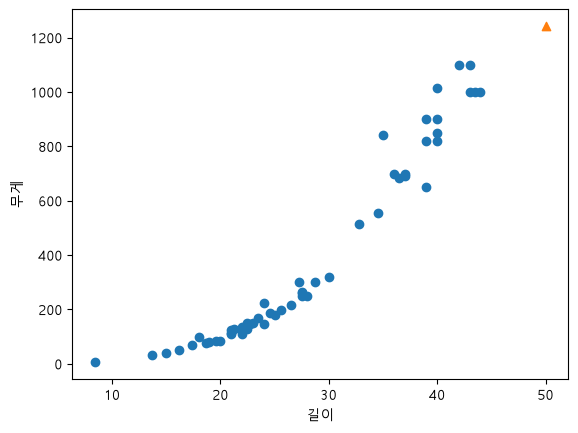

In [31]:
plt.scatter(perch_length,perch_weight)
plt.scatter(50,1241.83860323, marker='^')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

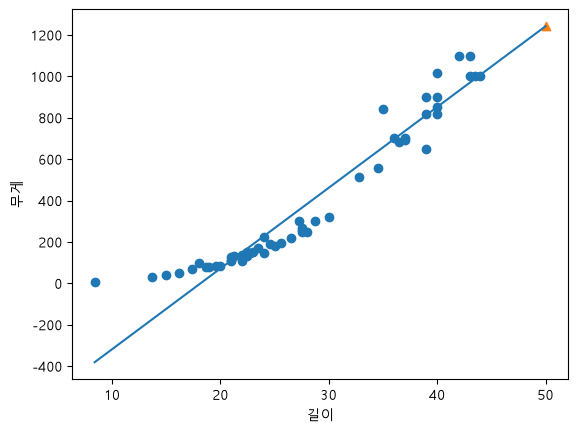

In [33]:
# 그래프에 회귀선 추가

plt.scatter(perch_length,perch_weight)
plt.scatter(50,1241.83860323, marker='^')
plt.plot([8.4,50],[8.4*lr.coef_+lr.intercept_, 50*lr.coef_+ lr.intercept_])
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

In [34]:
# study.csv파일과 선형회귀 모형을 이용해서 7시간 학습 시 성적을 예측
# 산점도에 점수와 직선을 표시

In [37]:
df = pd.read_csv('../data/study.csv', sep='\t')
df.head(2)

,our,score
0,0.5,10
1,1.2,8


In [ ]:
label = df['score'].values
data = df['our'].values

array([ 0.5,  1.2,  1.8,  2.4,  2.6,  3.2,  3.9,  4.4,  4.5,  5. ,  5.3,
        5.8,  6. ,  6.1,  6.2,  6.9,  7.2,  8.4,  8.6, 10. ])

In [40]:
train_data,test_data,train_label,test_label = \
train_test_split(data,label)

In [44]:
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)

In [45]:
lr = LinearRegression()
lr.fit(train_data,train_label)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[10.62]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.1353
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[8.7]


In [46]:
predict = lr.predict(test_data) 
predict

array([ 47.90655259,  41.53705855, 106.29358121,  19.24382944,
        89.30826379])

In [47]:
print('train정확도:',lr.score(train_data,train_label))
print('test정확도:',lr.score(test_data,test_label))

train정확도: 0.941927825494377
test정확도: 0.9655457773541188


In [49]:
indata = input('학습시간:')
indata = float(indata)
predict = lr.predict([[indata]])
predict

array([74.44611105])

In [50]:
print('기울기:',lr.coef_)
print('절편:',lr.intercept_)

기울기: [10.61582339]
절편: 0.13534734692437667


Text(0, 0.5, '성적')

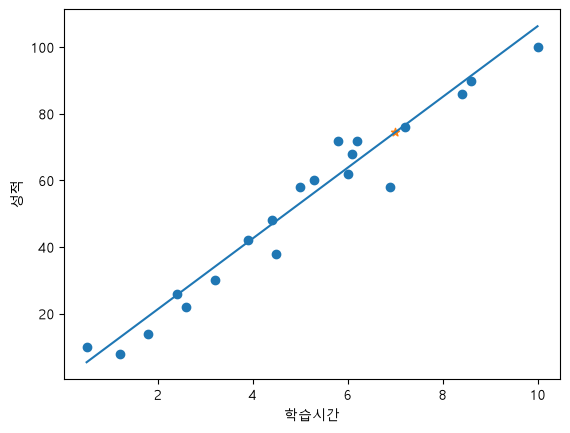

In [53]:
plt.scatter(data,label)
plt.scatter(7,74.44611105,marker='*')
plt.plot([0.5,10],[0.5*lr.coef_+lr.intercept_,10*lr.coef_+lr.intercept_])
plt.xlabel('학습시간')
plt.ylabel('성적')